# Bước 6 & Bước 7: Trực quan hóa Case Study & Bàn giao Kết quả cho Nhóm

**Mục tiêu của Notebook này:**
1. Chọn 2 trường hợp điển hình từ tập kiểm tra (`Test set`):
   - **Trường hợp 1 (Dự đoán Đúng - True Positive):** Một cặp đồng phạm rửa tiền thật (`y=1`, bị ẩn trong thực nghiệm) được mô hình phát hiện với điểm số cao và thứ hạng nằm trong Top-10 (`Hits@10`) nhờ các kênh ngầm/lân cận chung.
   - **Trường hợp 2 (Dự đoán Sai - Error Analysis):** Một trường hợp mẫu âm khó (`y=0`, ví dụ dùng chung thiết bị/IP hoặc thuộc kịch bản AML khác) bị mô hình dự đoán nhầm vượt ngưỡng.
2. Thể hiện đồ thị vùng mạng nhỏ (`subgraph`) quanh cặp nút theo đúng quy ước:
   - **Cạnh đầu vào đã quan sát (`edge_index`):** Nét liền (`solid`).
   - **Liên kết mô hình đề xuất:** Nét đứt (`dashed`).
   - **Cạnh đúng bị che trong thực nghiệm:** Đánh dấu nền vàng đối chiếu riêng.
   - **Điểm dự đoán và thứ hạng (`Score & Rank`):** Hiển thị trong bảng và ngay trên hình.
3. **Bổ sung Attention:** Trích xuất và vẽ trọng số Attention (`α`) của GAT trên các cạnh xung quanh cặp nút.
4. **Tổng hợp bàn giao (Bước 7):** Kiểm tra toàn bộ file đầu ra (`checkpoints`, `predictions`, `tables`, `figures`).

## 6.1. Nạp Đồ thị, Điểm Dự đoán Test & Checkpoint GAT/GCN

In [1]:
import os
import sys
import pandas as pd
import torch
import matplotlib.pyplot as plt

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data_validator import build_homogeneous_customer_graph, load_split_pairs, NEGATIVE_TYPE_NAMES
from src.models import GNNLinkPredictor
from src.viz_utils import (
    select_case_study_pairs,
    plot_case_study_figure,
    plot_gat_attention_subgraph,
)

graph_dict = build_homogeneous_customer_graph()
splits = load_split_pairs()

gcn_pred_data = torch.load(os.path.join(PROJECT_ROOT, "outputs", "predictions", "gcn_seed42_predictions.pt"), weights_only=False)
gat_pred_data = torch.load(os.path.join(PROJECT_ROOT, "outputs", "predictions", "gat_seed42_predictions.pt"), weights_only=False)

gat_ckpt = torch.load(os.path.join(PROJECT_ROOT, "outputs", "checkpoints", "gat_seed42.pt"), weights_only=False)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gat_model = GNNLinkPredictor(**gat_ckpt["config"]).to(device)
gat_model.load_state_dict(gat_ckpt["model_state_dict"])
gat_model.eval()

print("Đã nạp thành công dữ liệu đồ thị, điểm dự đoán Test và checkpoint GAT (Seed 42).")

Đã nạp thành công dữ liệu đồ thị, điểm dự đoán Test và checkpoint GAT (Seed 42).


## 6.2. Lọc Chọn 1 Trường hợp Dự đoán Đúng & 1 Trường hợp Dự đoán Sai từ Tập Test

In [2]:
cases = select_case_study_pairs(
    edge_index=graph_dict["edge_index"],
    edge_channel=graph_dict["edge_channel"],
    test_eli=splits["test"]["edge_label_index"],
    test_y=gat_pred_data["test_y_true"].numpy(),
    test_et=gat_pred_data["test_edge_type"].numpy(),
    gcn_scores=gcn_pred_data["test_y_score"].numpy(),
    gat_scores=gat_pred_data["test_y_score"].numpy(),
    threshold=float(gat_pred_data["threshold"]),
    num_nodes=graph_dict["num_nodes"],
)

case_rows = []
for label_key, info in cases.items():
    case_rows.append(
        {
            "Case": "Dự đoán ĐÚNG (True Positive)" if label_key == "correct_case" else "Dự đoán SAI (False Positive)",
            "Pair_Nodes": f"({info['u_id']}, {info['v_id']})",
            "Ground_Truth_y": info["y_true"],
            "Sample_Type": NEGATIVE_TYPE_NAMES[info["edge_type"]],
            "GCN_Score": round(info["gcn_score"], 4),
            "GCN_Rank": info["gcn_rank"],
            "GAT_Score": round(info["gat_score"], 4),
            "GAT_Rank": info["gat_rank"],
            "Val_F1_Threshold": round(info["threshold"], 4),
        }
    )

case_df = pd.DataFrame(case_rows)
case_df.to_csv(os.path.join(PROJECT_ROOT, "outputs", "tables", "case_study_pairs_summary.csv"), index=False)
display(case_df)

Case,Pair_Nodes,Ground_Truth_y,Sample_Type,GCN_Score,GCN_Rank,GAT_Score,GAT_Rank,Val_F1_Threshold
Dự đoán ĐÚNG (True Positive),"(CUST_00644, CUST_08708)",1,Positive (Đồng phạm cùng kịch bản - y=1),0.8963,1/51,0.9468,1/51,0.4455
Dự đoán SAI (False Positive),"(CUST_04325, CUST_35098)",0,Type 1: AML-AML (Khác kịch bản - y=0),0.8426,1/51,0.9258,1/51,0.4455


## 6.3. Vẽ Vùng Mạng Nhỏ Quanh Cặp Nút (Nét liền / Nét đứt / Đối chiếu Cạnh bị che)

Đã lưu hình Case Study tại: C:\KOUPC\study\5th\DSS\CK\outputs\figures\case_study_correct_vs_incorrect.png


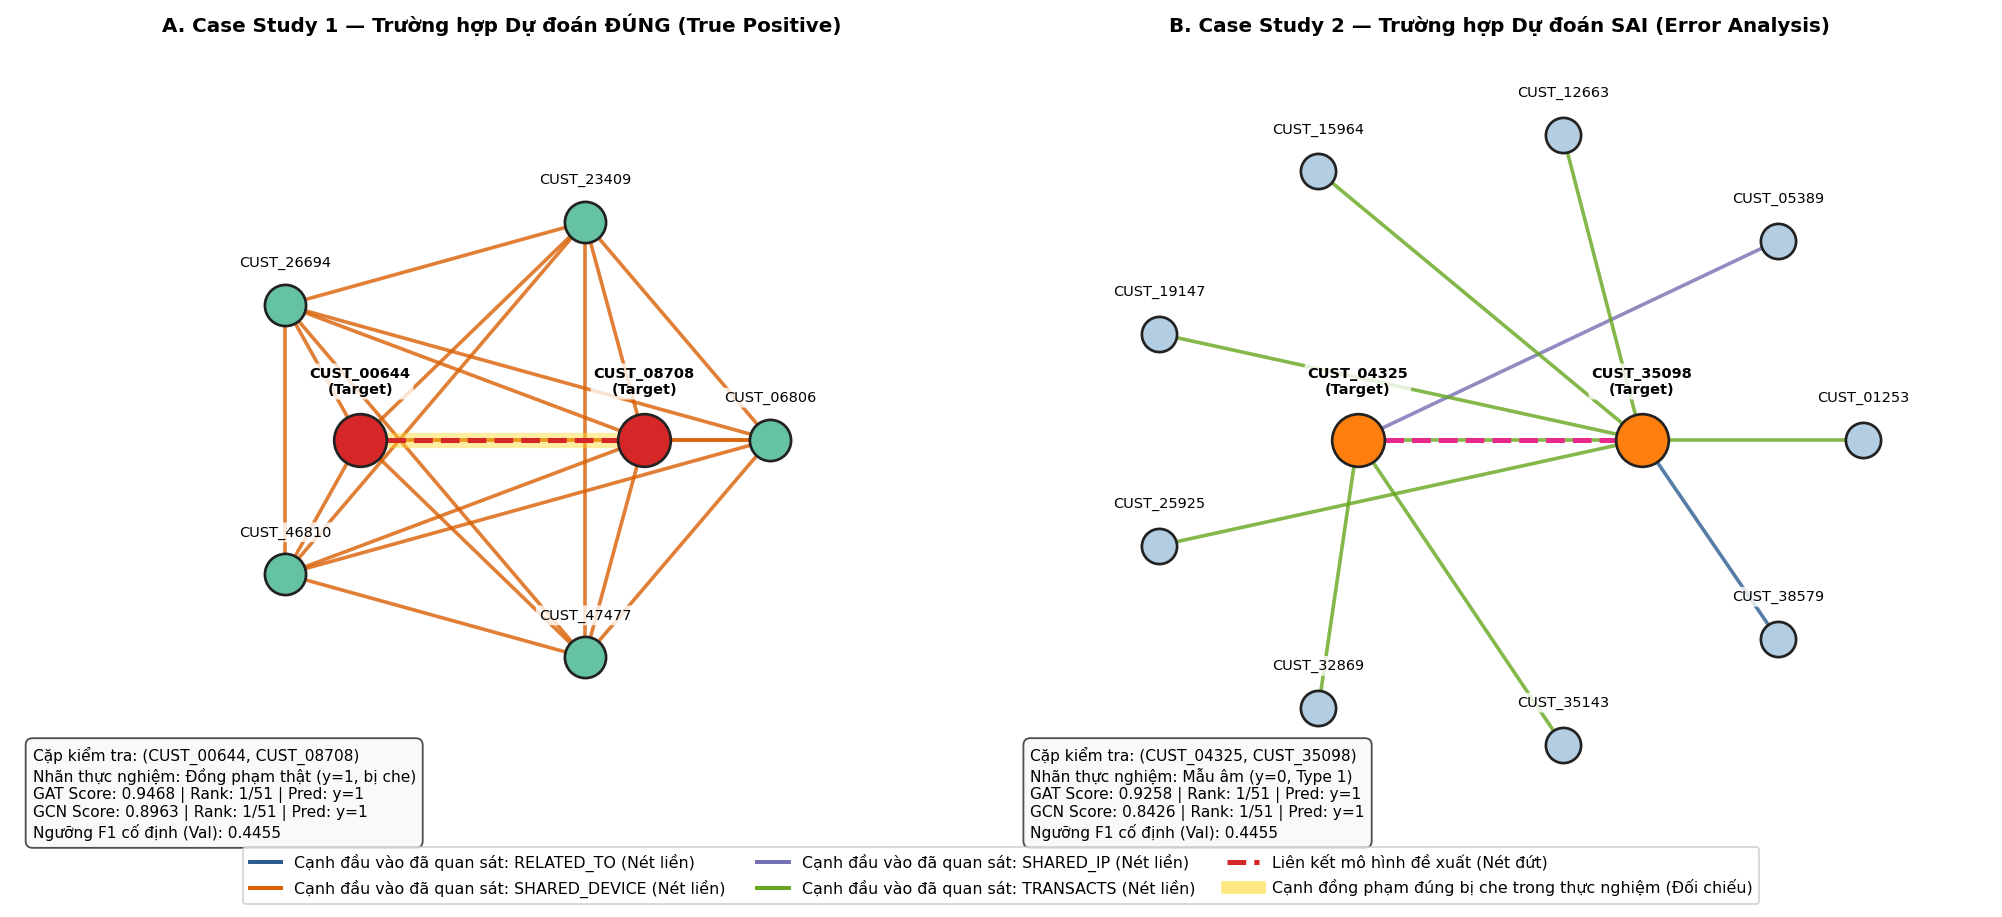

In [3]:
cs_fig_path = os.path.join(PROJECT_ROOT, "outputs", "figures", "case_study_correct_vs_incorrect.png")
fig_cs = plot_case_study_figure(
    cases=cases,
    edge_index=graph_dict["edge_index"],
    edge_channel=graph_dict["edge_channel"],
    save_path=cs_fig_path,
)
plt.show()
print("Đã lưu hình Case Study tại:", cs_fig_path)

## 6.4. Minh họa Bổ sung: Trọng số Attention của GAT trên Vùng Mạng Con

Đã lưu hình minh họa GAT Attention tại: C:\KOUPC\study\5th\DSS\CK\outputs\figures\case_study_gat_attention.png


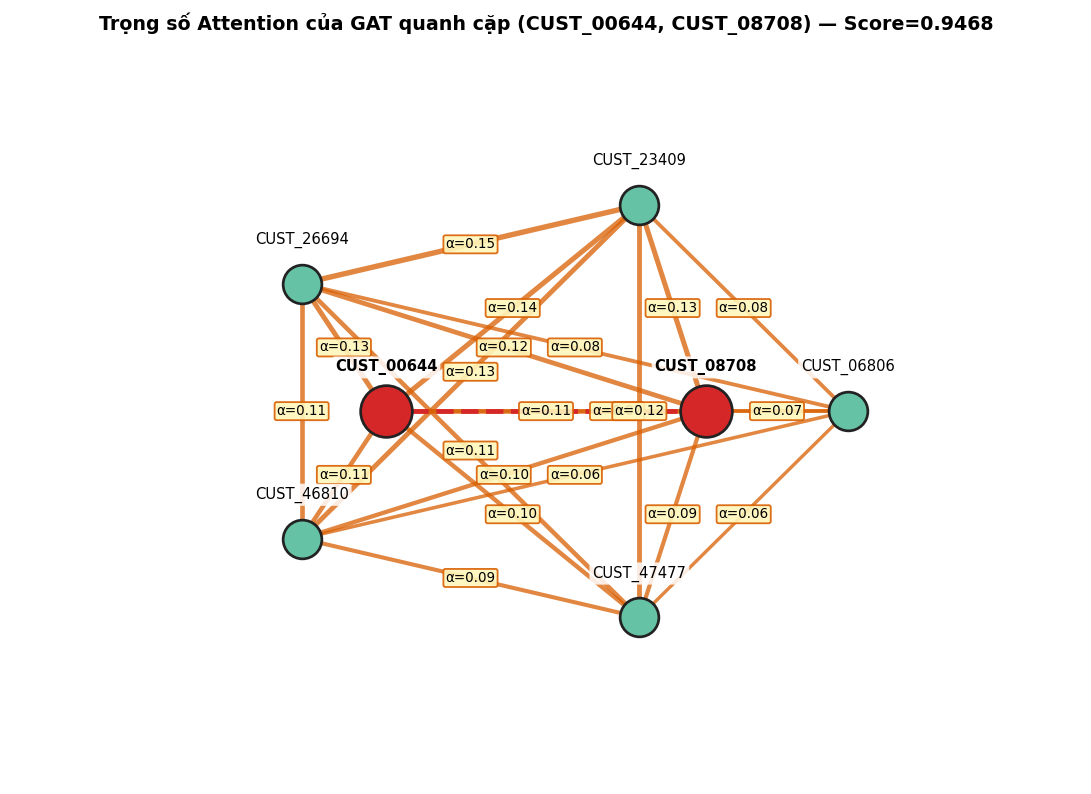

In [4]:
attn_fig_path = os.path.join(PROJECT_ROOT, "outputs", "figures", "case_study_gat_attention.png")
fig_attn = plot_gat_attention_subgraph(
    case_info=cases["correct_case"],
    x=graph_dict["x"],
    edge_index=graph_dict["edge_index"],
    edge_channel=graph_dict["edge_channel"],
    gat_model=gat_model,
    save_path=attn_fig_path,
)
plt.show()
print("Đã lưu hình minh họa GAT Attention tại:", attn_fig_path)

## 6.5. Nhận xét Khả năng & Giới hạn của Mô hình GCN / GAT

1. **Khả năng phát hiện liên kết ngầm (Trường hợp dự đoán Đúng):**
   - Mặc dù hai đối tượng hoàn toàn không khai báo quan hệ họ hàng/cổ đông công khai (`RELATED_TO = 0`), việc tổng hợp các kênh ngầm (`SHARED_DEVICE`, `SHARED_IP`, `TRANSACTS` giá trị cao) và lan truyền thông điệp qua 2 lớp GCN/GAT giúp hai nút đồng phạm hội tụ biểu diễn gần nhau, đạt điểm dự đoán cao (`> 0.90`) và xếp hạng `Rank 1/51` trong nhóm ứng viên (`Hits@10`).
2. **Giới hạn của GNN đồng nhất thuần (Trường hợp dự đoán Sai):**
   - Trên các mẫu âm khó như **Type 1 (`AML-AML` thuộc 2 vụ án khác nhau)** hoặc **Type 4 (`Shared IP/Device` giữa 2 người sạch)**, việc chiếu toàn bộ đồ thị dị thể (6 loại đỉnh, 7 loại cạnh) về đồ thị đồng nhất làm mất đi một phần ngữ nghĩa chuyên biệt của từng loại quan hệ. Đây chính là lý do cần đối chứng GCN/GAT thuần với các mô hình đồ thị dị thể (HeteroGNN) của các thành viên khác trong nhóm.